### Build a basic chatbot wih Langgraph (Graph Api)

In [29]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


# Shared State
class VideoState(TypedDict):
    transcript: str
    title: str
    content: str


# Node 1
def generate_transcript(state: VideoState):
    return {
        "transcript": "LangGraph helps build stateful AI agents."
    }


# Node 2
def generate_title(state: VideoState):
    transcript = state["transcript"]

    return {
        "title": f"Learn: {transcript[:30]}"
    }


# Node 3
def generate_content(state: VideoState):
    return {
        "content": (
            f"Title: {state['title']}\n"
            f"Transcript: {state['transcript']}"
        )
    }


# Create Graph
graph = StateGraph(VideoState)

# Register Nodes
graph.add_node("transcript", generate_transcript)
graph.add_node("title", generate_title)
graph.add_node("content", generate_content)

# Connect Nodes using Edges
graph.add_edge(START, "transcript")
graph.add_edge("transcript", "title")
graph.add_edge("title", "content")
graph.add_edge("content", END)

# Compile and Execute
app = graph.compile()

result = app.invoke({
    "transcript": "",
    "title": "",
    "content": ""
})

print(result)

{'transcript': 'LangGraph helps build stateful AI agents.', 'title': 'Learn: LangGraph helps build stateful', 'content': 'Title: Learn: LangGraph helps build stateful\nTranscript: LangGraph helps build stateful AI agents.'}


In [30]:
from typing import Annotated
from typing_extensions import TypedDict


from langgraph.graph import StateGraph , START , END

from langgraph.graph.message import add_messages




In [31]:
class State(TypedDict):
    messages:Annotated[list, add_messages]
    

    
    

In [32]:
import os 
from dotenv import load_dotenv
load_dotenv()

print("API Key loaded:", bool(os.getenv("GROQ_API_KEY")))

API Key loaded: True


In [48]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model


llm=ChatGroq(
model="openai/gpt-oss-20b",
    api_key=os.getenv("GROQ_API_KEY"),

)
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000023FDFEBEC10>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023FDFEBF390>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [47]:
llm=init_chat_model("groq:openai/gpt-oss-20b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.7.0', 'langchain': '1.4.7'}}, profile={'name': 'GPT OSS 20B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x0000023FDFEC18D0>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x0000023FDFC9D250>, model_name='openai/gpt-oss-20b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [55]:

## node functionality

def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [57]:
graph_builder = StateGraph(State)

graph_builder.add_node("llmChatbot",chatbot)

graph_builder.add_edge(START, "llmChatbot")
graph_builder.add_edge("llmChatbot", END)

## compile graph
graph=graph_builder.compile()


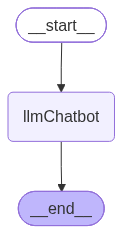

In [58]:
## visualize the graph

from IPython.display import Image ,display
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [61]:
response=graph.invoke({"messages":"hi"})
response["messages"][-1].content

'Hi there! 👋 How can I assist you today?'